# c4 · Step 4: Initial model and sanity checks

Goals:
1. A small, standard CNN that **provably learns** (it can overfit a tiny set, and it beats the 0.25 baselines).
2. Decide the **early-stopping monitor** (left open in c2) with a fair test.
3. Measure **seed noise** σ_seed, which completes the "meaningful difference" rule from c2.

All later notebooks change *one thing at a time* relative to this model.

In [1]:
import sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
sys.path.insert(0, ".")
from dataclasses import replace
from sklearn.metrics import balanced_accuracy_score
from lib.train import Config, run, build_model, RESULTS, summary
from lib.models import n_params, n_conv_layers
from lib.evaluation import bootstrap_ci
from lib.data import SEED, CLASSES

## 1. The initial model ("semi-guessed" standard defaults)

| Part | Choice | Reason |
|---|---|---|
| input | 1-channel grayscale, head crop, 128×128 | c1/c3 provisional choice (tested in c5) |
| body | stem conv + 4 stages × 1 conv (3×3, BatchNorm, ReLU), max-pool between stages, widths 16-32-64-128 | the most common small-CNN recipe |
| head | global average pool → linear (4 classes), softmax inside the loss | far fewer parameters than flatten + dense |
| training | Adam, lr 1e-3, batch 64, cross-entropy, no schedule, no augmentation, no weight decay | standard defaults; tuned in c6 |

In [2]:
BASE = Config(exp="c4", name="initial")
m = build_model(BASE, 1)
print(m)
print(f"parameters: {n_params(m):,} | conv layers: {n_conv_layers(m)}")

CNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): Block(
      (body): Sequential(
        (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
    )
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Block(
      (body): Sequential(
        (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
    )
    (5): MaxPool2d(ke

## 2. Sanity check: can it overfit 64 images?
If the pipeline (labels, loss, optimiser, data flow) is correct, the model must reach about 100 % **training**
accuracy on a tiny set. Val accuracy is irrelevant here.

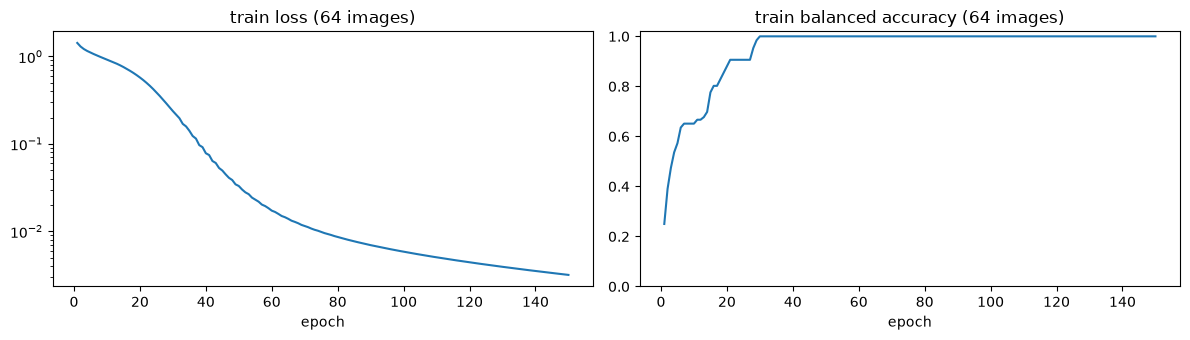

final train loss 0.0032, train bal. acc 1.000, first epoch at 100 %: 30


In [3]:
r = run(replace(BASE, name="overfit64", train_n=64, epochs=150, patience=1000))
h = pd.DataFrame(r["history"])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(h.epoch, h.train_loss); ax[0].set(yscale="log", title="train loss (64 images)", xlabel="epoch")
ax[1].plot(h.epoch, h.train_bal_acc); ax[1].set(title="train balanced accuracy (64 images)", xlabel="epoch", ylim=(0, 1.02))
plt.tight_layout(); plt.show()
print(f"final train loss {h.train_loss.iloc[-1]:.4f}, train bal. acc {h.train_bal_acc.iloc[-1]:.3f}, "
      f"first epoch at 100 %: {int(h.epoch[h.train_bal_acc >= 0.999].min()) if (h.train_bal_acc >= 0.999).any() else None}")

**Result.** Training loss falls to 0.003 and training balanced accuracy reaches 100 % at epoch 30 on 64 images.
The labels, loss, optimiser and data flow are wired correctly, and the model has enough capacity to memorise.
**Pass.**

## 3. Full training, long runs, 5 seeds
Each run trains for 60 epochs **without** early stopping and stores the val probabilities of every epoch. That
gives the full curves, and lets section 4 replay any early-stopping rule afterwards.

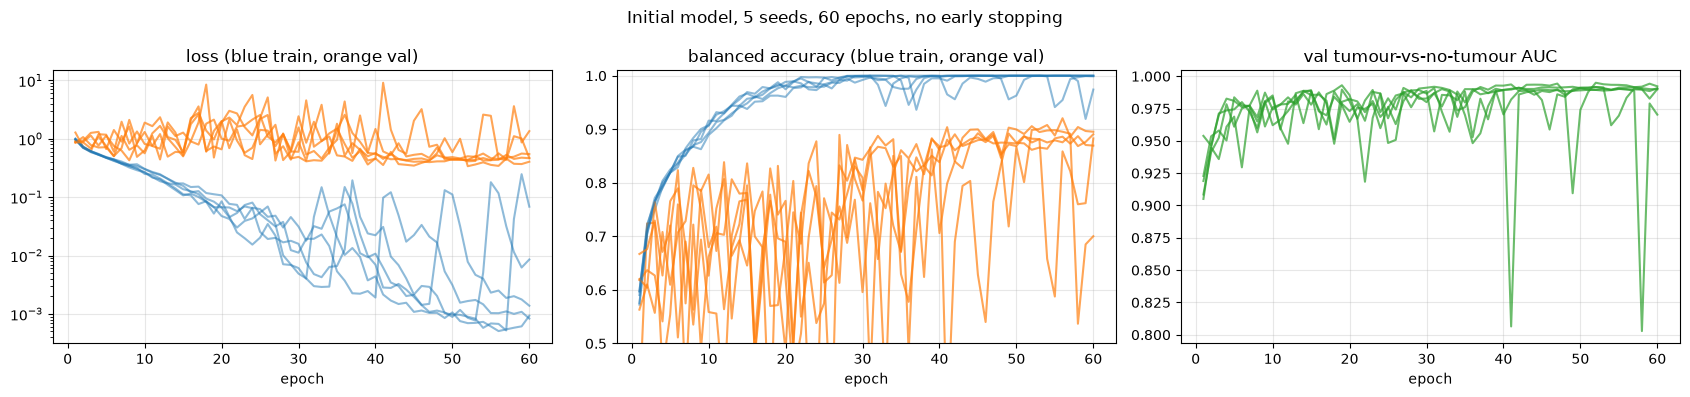

epoch of min val loss per seed: [54, 47, 31, 37, 52]
epoch of max val bal. acc per seed: [52, 42, 60, 49, 56]
epoch-to-epoch jitter of val bal. acc (std of differences, epochs 15-60): 0.1454
s/epoch: 3.8


In [4]:
SEEDS = [SEED + i for i in range(5)]
long = {s: run(replace(BASE, name=f"long_s{s}", epochs=60, patience=1000, seed=s, extra={"save_epoch_probs": True}))
        for s in SEEDS}
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for s, r in long.items():
    h = pd.DataFrame(r["history"])
    axes[0].plot(h.epoch, h.train_loss, "C0", alpha=0.5); axes[0].plot(h.epoch, h.val_loss, "C1", alpha=0.7)
    axes[1].plot(h.epoch, h.train_bal_acc, "C0", alpha=0.5); axes[1].plot(h.epoch, h.val_bal_acc, "C1", alpha=0.7)
    axes[2].plot(h.epoch, h.val_tumor_auc, "C2", alpha=0.7)
axes[0].set(title="loss (blue train, orange val)", xlabel="epoch", yscale="log")
axes[1].set(title="balanced accuracy (blue train, orange val)", xlabel="epoch", ylim=(0.5, 1.01))
axes[2].set(title="val tumour-vs-no-tumour AUC", xlabel="epoch")
for a in axes: a.grid(alpha=0.3)
plt.suptitle("Initial model, 5 seeds, 60 epochs, no early stopping"); plt.tight_layout(); plt.show()
H = pd.concat([pd.DataFrame(r["history"]).assign(seed=s) for s, r in long.items()])
print("epoch of min val loss per seed:", H.loc[H.groupby("seed").val_loss.idxmin()].epoch.tolist() if False else
      [int(pd.DataFrame(r["history"]).val_loss.idxmin()) + 1 for r in long.values()])
print("epoch of max val bal. acc per seed:", [int(pd.DataFrame(r["history"]).val_bal_acc.idxmax()) + 1 for r in long.values()])
print(f"epoch-to-epoch jitter of val bal. acc (std of differences, epochs 15-60): "
      f"{H[H.epoch >= 15].groupby('seed').val_bal_acc.apply(lambda s: s.diff().std()).mean():.4f}")
print(f"s/epoch: {np.mean([r['sec_per_epoch'] for r in long.values()]):.1f}")

**What the curves show.**
* **Train** loss drops steadily, and train balanced accuracy is about 100 % from epoch 25-30. After that the model
  has memorised the training set, with occasional spikes (Adam at a constant lr 1e-3 jumping out of the minimum).
* **Val** balanced accuracy is extremely jumpy in the first 25 epochs (0.4-0.85 between consecutive epochs; std of
  the epoch-to-epoch change is 0.145). It only settles around 0.87-0.90 **after** the training set is fitted.
  Val AUC is high early (about 0.98), so the jumpiness is mostly in the *argmax decision*, not in the ranking.
* The best val epochs come late: 31-54 for val loss, 42-60 for val balanced accuracy.

**Consequences.**
* An early-stopping rule that stops in the jumpy phase will stop on noise. This is a problem for the patience
  setting, not just the monitor (section 4).
* The constant learning rate is a likely cause of the jumpiness. Learning rate and schedule are tested in c6.

## 4. Fair test of the early-stopping monitor
Picking the epoch with the best val balanced accuracy and then *reporting* that same number is optimistically
biased. A fair comparison needs data the choice did not see. So:

* split clean val randomly into halves A and B (stratified), 200 times
* on **A**, choose the epoch with each rule
* on **B**, measure the balanced accuracy of that epoch

Rules compared: min val loss, max val balanced accuracy, and max of a 3-epoch moving average of balanced accuracy
(a smoother variant). The "patience" question is replayed the same way: with patience P, training would have
stopped P epochs after the last improvement on A.

In [5]:
from sklearn.model_selection import StratifiedShuffleSplit

def replay(rule, P, prob, y, A):
    loss = np.array([-np.log(p[A][np.arange(len(A)), y[A]] + 1e-7).mean() for p in prob.astype(np.float32)])
    acc = np.array([balanced_accuracy_score(y[A], p[A].argmax(1)) for p in prob])
    score = {"val_loss": -loss, "val_bal_acc": acc,
             "bal_acc_ma3": pd.Series(acc).rolling(3, min_periods=1).mean().to_numpy()}[rule]
    best, best_ep, bad = -np.inf, 0, 0
    for e, sc in enumerate(score):
        if sc > best: best, best_ep, bad = sc, e, 0
        else: bad += 1
        if bad >= P: break
    return best_ep

rows = []
for s in SEEDS:
    d = np.load(RESULTS / "c4" / f"long_s{s}_epochs.npz"); prob, y = d["prob"], d["y"]
    splits = StratifiedShuffleSplit(n_splits=40, test_size=0.5, random_state=s).split(y, y)
    for k, (A, B) in enumerate(splits):
        for rule in ["val_loss", "val_bal_acc", "bal_acc_ma3"]:
            for P in [5, 10, 20, 60]:
                e = replay(rule, P, prob, y, A)
                rows.append(dict(seed=s, split=k, rule=rule, patience=P, epoch=e + 1,
                                 bal_acc_B=balanced_accuracy_score(y[B], prob[e][B].argmax(1))))
R = pd.DataFrame(rows)
tab = R.groupby(["rule", "patience"]).agg(bal_acc_on_B=("bal_acc_B", "mean"), sd=("bal_acc_B", "std"),
                                          mean_stop_epoch=("epoch", "mean")).round(4)
display(tab.unstack("patience"))

bal_acc_on_B                              sd                  \
patience              5       10      20      60      5       10      20   
rule                                                                       
bal_acc_ma3       0.7115  0.7566  0.8838  0.8869  0.1055  0.0519  0.0250   
val_bal_acc       0.7956  0.8191  0.8789  0.8902  0.0294  0.0336  0.0317   
val_loss          0.7948  0.8177  0.8395  0.8758  0.0333  0.0303  0.0364   

                    mean_stop_epoch                          
patience         60              5       10      20      60  
rule                                                         
bal_acc_ma3  0.0194            9.75  12.580  50.315  52.360  
val_bal_acc  0.0185            7.41  12.365  41.865  50.370  
val_loss     0.0259            6.82  11.690  20.730  40.905

**Result (mean balanced accuracy on the unseen half B, 5 seeds × 40 random splits).**
* **Patience matters more than the monitor.** With patience 5-10, every rule stops around epoch 7-13, in the
  jumpy phase, and reaches only 0.71-0.82. With patience 20 the rules reach 0.84-0.88; with 60 (= train 60 epochs,
  keep the best) 0.88-0.89.
* **val balanced accuracy ≥ val loss at every patience** (0.879 vs 0.840 at patience 20; 0.890 vs 0.876 at 60).
  Val loss keeps rising from over-confidence while the predictions still improve, so it stops too early.
* The 3-epoch moving average is no better than the raw balanced accuracy at patience ≥ 20, and is worse below.

**Decision: monitor = val balanced accuracy, patience 20, at most 60 epochs.** This almost matches "always train
60 epochs and keep the best" (0.879 vs 0.890) while saving time. Patience 60 would cost about 20 % more compute for
about +1 pp. The bias this rule could have (picking a lucky epoch on the same data it reports) was measured
directly by the A/B split above, and the rule still wins on data it did not see.

## 5. Seed noise σ_seed
Same config, 5 seeds, using the chosen rule (applied to the whole clean val, as in every later run).

In [6]:
MONITOR, PATIENCE, EPOCHS = "val_bal_acc", 20, 60   # decided in section 4
seed_runs = {s: run(replace(BASE, name=f"seed_s{s}", seed=s, monitor=MONITOR, patience=PATIENCE, epochs=EPOCHS)) for s in SEEDS}
S = summary(seed_runs)
display(S.astype(float).round(3))
sigma = S.bal_acc.astype(float).std()
print(f"mean bal. acc {S.bal_acc.mean():.4f}, sigma_seed {sigma:.4f} -> adoption threshold 2*sigma = {2 * sigma:.4f}")
r0 = seed_runs[SEED]
y = np.load(RESULTS / "c4" / f"seed_s{SEED}_val.npz")["y"]; p = np.load(RESULTS / "c4" / f"seed_s{SEED}_val.npz")["prob"]
lo, hi = bootstrap_ci(y, p.argmax(1))
print(f"seed {SEED}: bal. acc {r0['val']['bal_acc']:.3f} [95% CI {lo:.3f}, {hi:.3f}] vs dumb baselines 0.25")
print("per-class recall:", r0["val"]["recall"])
print("confusion (rows true, cols pred):", CLASSES); print(np.array(r0["val"]["confusion"]))
import json
from lib.data import ARTIFACTS
_ = (ARTIFACTS / "sigma_seed.json").write_text(json.dumps({"sigma": float(sigma), "seeds": SEEDS, "mean": float(S.bal_acc.mean())}))
_ = (ARTIFACTS / "protocol.json").write_text(json.dumps({"monitor": MONITOR, "patience": PATIENCE, "epochs": EPOCHS}))
from lib.report import log_progress
_ = log_progress("c4 initial", list(seed_runs.values())[:3])

,bal_acc,macro_f1,tumor_auc,no_tumor_rec,best_ep,epochs,params,s/ep
1738,0.906,0.905,0.989,0.906,52.0,60.0,100244.0,3.815
1739,0.891,0.877,0.991,0.958,42.0,60.0,100244.0,3.800
1740,0.891,0.882,0.991,0.927,60.0,60.0,100244.0,3.796
1741,0.839,0.845,0.984,0.792,12.0,32.0,100244.0,3.789
1742,0.921,0.918,0.993,0.927,56.0,60.0,100244.0,3.802


mean bal. acc 0.8892, sigma_seed 0.0309 -> adoption threshold 2*sigma = 0.0619


seed 1738: bal. acc 0.906 [95% CI 0.883, 0.927] vs dumb baselines 0.25
per-class recall: {'glioma': 0.9038, 'meningioma': 0.8657, 'no_tumor': 0.9062, 'pituitary': 0.9471}
confusion (rows true, cols pred): ['glioma', 'meningioma', 'no_tumor', 'pituitary']
[[282  26   3   1]
 [ 18 187   5   6]
 [  2   4  87   3]
 [  3   7   1 197]]


**Result.** Mean val balanced accuracy is 0.889 over 5 seeds, with **σ_seed = 0.031**. Four seeds land at 0.89-0.92.
Seed 1741 is the outlier (0.839): its best epoch was 12, and it then went 20 epochs without beating that lucky
early peak, so early stopping ended it at epoch 32. This is the failure mode from section 4, and it happens even
at patience 20, though much more rarely than at 5-10.

Seed 1738 (the designated seed) reaches 0.906 [0.883, 0.927]. Every class is well above the 0.25 of the dumb
baselines. Glioma and meningioma are mostly confused with each other (26 + 18 errors). no_tumor is rarely
confused with anything (9 errors in 96).

**What σ_seed means for later decisions.** With 3 seeds per option, a difference of means counts only if it is
larger than 2·σ·√(1/3 + 1/3) = **0.050**, i.e. about 5 pp of balanced accuracy. That is a high bar. Most single
changes will be "ties", and the rule then keeps the simpler or default option. This is deliberate: on 832 val
images and with this much seed noise, smaller differences cannot be told apart from luck without many more
seeds than this machine can afford.

**Update (round r2).** σ_seed was measured on this untuned model (lr 1e-3, jumpy val curve). The tuned models of
c6 to c8 have a seed sd of 0.004 to 0.009, so 5 pp was far too high a bar: in round r1 it rejected every change.
From round r2 the option with the highest mean wins (see c2). σ_seed is kept as the reported noise reference.

## Decisions

| Decision | Choice | Evidence |
|---|---|---|
| Sanity check | passed | memorises 64 images to 100 % (section 1) |
| Early-stopping monitor | val balanced accuracy | beats val loss at every patience on unseen half B (section 4) |
| Patience / epoch cap | 20 / 60 | patience 5-10 stops in the jumpy phase; 20 gets within 1 pp of "train 60, keep best". Round r3 raised the cap to 200 from c5 on: no gain (history notebook), so 60 stays |
| Noise level | σ_seed = 0.031 | 5 seeds (section 5) |
| Adoption rule | Δ > 2·σ·√(1/n_a + 1/n_b) (0.050 for 3 vs 3) | from c2, completed with σ_seed. Rounds r0, r1 only; from r2 the highest mean wins |
| Starting point | 0.896 (mean of seeds 1738-1740) | the baseline every later step must beat |

Open issues carried forward: constant LR 1e-3 is a likely cause of the jumpy val curve (c6), and
glioma/meningioma confusion is the main error (c7/c8).